# Meshgrid test: Python vs MATLAB

Compare the **saved outputs** of the two independent meshgrid calculations.

1. Run all cells in `meshgrid_test.ipynb` to export `inputs.mat` and `python_results.mat`.
2. Run all sections of `meshgrid_test.mlx` in MATLAB to export `matlab_results.mat`.
3. Run this notebook with **Restart Kernel and Run All**.

This notebook only reads the result files: it does not rerun either calculation, start MATLAB, or overwrite any files. Rerun **both** implementations after changing inputs. The result files contain no input fingerprint, so this comparison cannot establish that they belong to the same input case.


In [1]:
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import Markdown, display

# Find the project from the workspace, project, test, or notebook folder.
current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "1.meshgrid_test"

# Use the same dashed gray grid as the Python meshgrid notebook.
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})


## 1. Load the two result files

The paths and modification times help identify the files being compared; timestamps alone do not prove that their inputs match. Scalars, vectors, and matrices are initially loaded with their stored dimensions.


In [2]:
python_file = test_directory / "python_results.mat"
matlab_file = test_directory / "matlab_results.mat"

for result_file in (python_file, matlab_file):
    if not result_file.is_file():
        raise FileNotFoundError(
            f"Missing {result_file}. Run both meshgrid tests before comparing."
        )
    modified = datetime.fromtimestamp(result_file.stat().st_mtime)
    print(f"{result_file.name}: {result_file}")
    print(f"  Last modified (local time): {modified:%Y-%m-%d %H:%M:%S}")

python_results = loadmat(python_file)
matlab_results = loadmat(matlab_file)


python_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\1.meshgrid_test\python_results.mat
  Last modified (local time): 2026-10-13 17:29:58
matlab_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\1.meshgrid_test\matlab_results.mat
  Last modified (local time): 2026-10-13 18:16:49


## 2. Comparison rules

All 18 reference/grid outputs are checked. The calculations themselves are not repeated here.

- Scalars must contain one value. Only declared vectors may ignore row/column orientation.
- `Nesz` must remain a matrix with one row per grid node and two columns.
- Python `Nesz` stores **zero-based, stop-exclusive** bounds; MATLAB stores **one-based, inclusive** bounds. Add 1 to the **first column only**, on a copy.
- `dN` and `Nesz` must be integer-valued and match **exactly**, regardless of storage dtype.
- Other values pass when `abs(Python - MATLAB) <= atol + rtol * abs(MATLAB)` at **every** entry. MATLAB is the reference for this tolerance.
- Missing variables, unexpected dimensions, nonnumeric values, NaN, or infinity cannot pass.

The absolute tolerance is in each quantity's stored units. Review tolerances if the test case changes; do not increase them just to hide discrepancies. An additional exported variable is marked **NOT TESTED** until it is added to the comparison list.


In [3]:
rtol = 1e-10
atol = 1e-12

# Name: (expected structure, units)
variables = {
    "Iz0":   ("scalar", "A"),
    "I0":    ("scalar", "A"),
    "U0":    ("scalar", "kV"),
    "s":     ("scalar", "1"),
    "vetoc": ("vector", "1"),
    "vn1":   ("vector", "1"),
    "gama":  ("scalar", "1"),
    "w":     ("scalar", "rad/s"),
    "w0":    ("vector", "rad/s"),
    "k0":    ("vector", "1/mm"),
    "betae": ("scalar", "1/mm"),
    "dz":    ("scalar", "mm"),
    "zi":    ("vector", "mm"),
    "z":     ("vector", "1"),
    "dt":    ("scalar", "1"),
    "rcvs":  ("vector", "mm"),
    "dN":    ("scalar", "intervals"),
    "Nesz":  ("matrix", "indices"),
}
exact_variables = ("dN", "Nesz")


In [4]:
comparison = []
pairs = {}  # Validated copies used by the plots; saved arrays stay unchanged.

for name, (structure, units) in variables.items():
    python_values = python_results.get(name)
    matlab_values = matlab_results.get(name)
    row = {
        "name": name,
        "units": units,
        "python_shape": None if python_values is None else python_values.shape,
        "matlab_shape": None if matlab_values is None else matlab_values.shape,
        "max_absolute": None,
        "max_relative": None,
        "status": "NOT TESTED",
        "note": "",
    }
    comparison.append(row)

    if python_values is None or matlab_values is None:
        row["note"] = "Missing variable in one or both result files."
        continue

    # These meshgrid outputs are real numbers, not text, objects, or complex fields.
    if any(values.dtype.kind not in "iuf" for values in (python_values, matlab_values)):
        row["note"] = "Expected real numeric values."
        continue

    shape_ok = True
    for values, results in ((python_values, python_results),
                            (matlab_values, matlab_results)):
        if structure == "scalar":
            shape_ok = shape_ok and values.shape == (1, 1)
        elif structure == "vector":
            shape_ok = shape_ok and values.ndim == 2 and 1 in values.shape and values.size > 0
        else:
            # Nesz has one [first, last] pair per longitudinal node.
            zi_values = results.get("zi", np.array([]))
            shape_ok = shape_ok and zi_values.size > 0 and values.shape == (zi_values.size, 2)

    if not shape_ok:
        row["note"] = f"Unexpected {structure} dimensions."
        continue

    # Float copies also avoid unsigned-integer subtraction in the error calculation.
    python_values = python_values.astype(float)
    matlab_values = matlab_values.astype(float)
    if structure != "matrix":
        python_values = python_values.reshape(-1)
        matlab_values = matlab_values.reshape(-1)

    if python_values.shape != matlab_values.shape:
        row["note"] = "Dimensions differ after allowed vector-orientation adjustment."
        continue

    if not (np.all(np.isfinite(python_values)) and np.all(np.isfinite(matlab_values))):
        row["note"] = "NaN or infinity found."
        continue

    if name in exact_variables:
        if any(np.any(values != np.floor(values)) for values in (python_values, matlab_values)):
            row["note"] = "Counts and indices must be integer-valued."
            continue

    if name == "Nesz":
        python_values[:, 0] += 1  # Only the starting index changes convention.

    pairs[name] = (python_values, matlab_values)
    absolute_error = np.abs(python_values - matlab_values)
    row["max_absolute"] = np.max(absolute_error)

    # Relative error is defined only where the MATLAB reference is nonzero.
    nonzero = matlab_values != 0
    if np.any(nonzero):
        row["max_relative"] = np.max(
            absolute_error[nonzero] / np.abs(matlab_values[nonzero])
        )

    if name in exact_variables:
        passed = np.array_equal(python_values, matlab_values)
        row["note"] = "Exact values"
        if name == "Nesz":
            row["note"] += "; Python first column + 1"
    else:
        tolerance = atol + rtol * np.abs(matlab_values)
        passed = np.all(absolute_error <= tolerance)
        row["note"] = "Absolute + relative tolerance"

    row["status"] = "PASS" if passed else "FAIL"

# Do not silently ignore a new output added to either implementation.
exported_names = {
    name for results in (python_results, matlab_results)
    for name in results if not name.startswith("__")
}
extra_names = sorted(exported_names - variables.keys())
all_passed = all(row["status"] == "PASS" for row in comparison) and not extra_names


## 3. Numerical summary

**Max absolute error** uses the units listed in the table. **Max relative error** is dimensionless and is calculated only over nonzero MATLAB entries (a dash means there are none). Entries whose MATLAB value is zero are still checked using `atol`. A small maximum absolute error is not sufficient on its own: the tolerance is checked separately at each entry.


In [5]:
def format_error(value):
    return "-" if value is None else f"{value:.3e}"


table = [
    "| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |",
    "|---|---|---|---|---|---|---|---|",
]
for row in comparison:
    table.append(
        f"| {row['name']} | {row['units']} | {row['python_shape']} | {row['matlab_shape']} "
        f"| {format_error(row['max_absolute'])} | {format_error(row['max_relative'])} "
        f"| {row['status']} | {row['note']} |"
    )
display(Markdown("\n".join(table)))

if extra_names:
    print("NOT TESTED: unexpected exported variables:", ", ".join(extra_names))

passed_count = sum(row["status"] == "PASS" for row in comparison)
print(f"Tolerance for floating-point quantities: rtol={rtol:g}, atol={atol:g}")
print(f"{passed_count}/{len(variables)} expected quantities passed.")
print("Overall: PASS" if all_passed else "Overall: NOT PASSED — inspect the table above.")


| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |
|---|---|---|---|---|---|---|---|
| Iz0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| I0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| U0 | kV | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| s | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| vetoc | 1 | (1, 128) | (1, 128) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| vn1 | 1 | (1, 128) | (1, 128) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| gama | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| w | rad/s | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| w0 | rad/s | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| k0 | 1/mm | (1, 5) | (1, 5) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| betae | 1/mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| dz | mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| zi | mm | (1, 3806) | (3806, 1) | 4.547e-13 | 2.334e-16 | PASS | Absolute + relative tolerance |
| z | 1 | (1, 3806) | (3806, 1) | 1.421e-14 | 2.343e-16 | PASS | Absolute + relative tolerance |
| dt | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| rcvs | mm | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| dN | intervals | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| Nesz | indices | (3806, 2) | (3806, 2) | 0.000e+00 | 0.000e+00 | PASS | Exact values; Python first column + 1 |

Tolerance for floating-point quantities: rtol=1e-10, atol=1e-12
18/18 expected quantities passed.
Overall: PASS


## 4. Grid overlays and differences

The left panels overlay both outputs. The right panels show **Python minus MATLAB**, so tiny differences remain visible even when the curves overlap. The horizontal axis is the node's **zero-based Python index**, not a physical coordinate.

The table, not visual overlap, determines whether the results pass. Missing or incompatible arrays are not plotted.


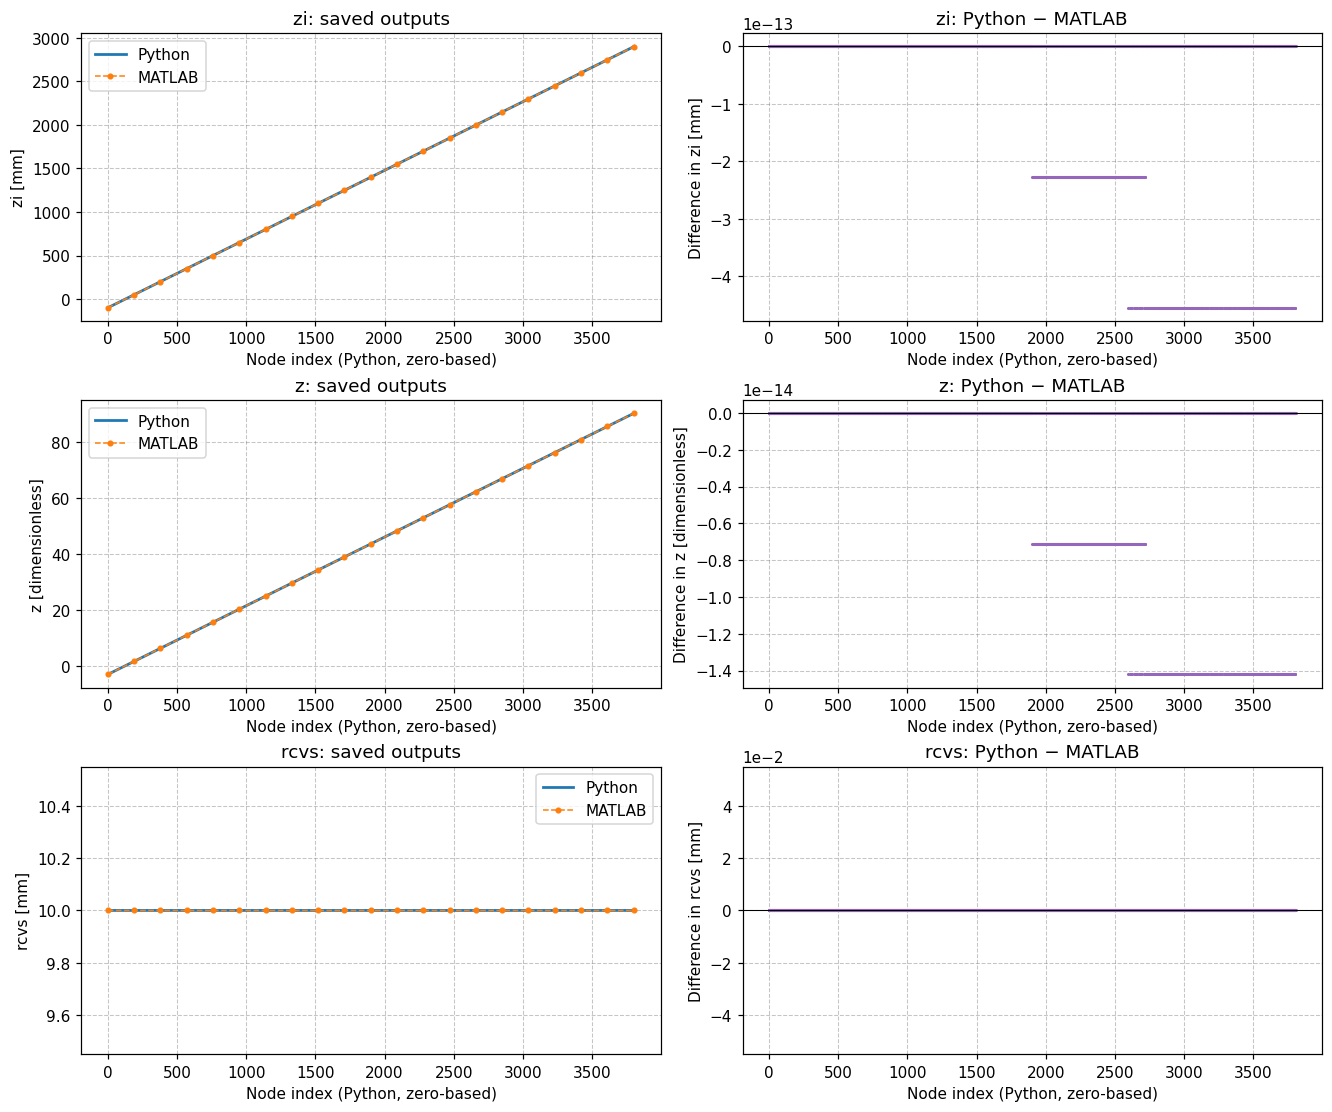

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10), constrained_layout=True)

for row, (name, label) in enumerate([
    ("zi", "zi [mm]"),
    ("z", "z [dimensionless]"),
    ("rcvs", "rcvs [mm]"),
]):
    if name not in pairs:
        for ax in axes[row]:
            ax.text(0.5, 0.5, f"{name}: comparison unavailable",
                    ha="center", va="center", transform=ax.transAxes)
            ax.set_xlabel("Node index (Python, zero-based)")
        continue

    python_values, matlab_values = pairs[name]
    nodes = np.arange(python_values.size)

    ax = axes[row, 0]
    ax.plot(nodes, python_values, label="Python", linewidth=1.8)
    ax.plot(nodes, matlab_values, "--o", label="MATLAB", markersize=3,
            markevery=max(1, nodes.size // 20), linewidth=1)
    ax.set_title(f"{name}: saved outputs")
    ax.set_ylabel(label)
    ax.legend()

    ax = axes[row, 1]
    ax.plot(nodes, python_values - matlab_values, ".", markersize=2, color="tab:purple")
    ax.axhline(0, color="black", linewidth=0.7)
    ax.set_title(f"{name}: Python − MATLAB")
    ax.set_ylabel(f"Difference in {label}")
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useOffset=False)

    for ax in axes[row]:
        ax.set_xlabel("Node index (Python, zero-based)")
        ax.grid(True, color="gray", linestyle="--", linewidth=0.7, alpha=0.45)

plt.show()


## 5. Check the source-window indexing explicitly

For example, Python `[0, 53]` selects `zi[0:53]`: 53 nodes. MATLAB `[1, 53]` selects `zi(1:53)`: the same 53 nodes.

The table below shows representative entrance, middle, and exit windows. The numerical comparison above checks **all rows**, not just these examples. The original arrays in the result files are never modified.


In [7]:
if "Nesz" in pairs:
    python_bounds, matlab_bounds = pairs["Nesz"]
    selected_nodes = np.unique([0, len(python_bounds) // 2, len(python_bounds) - 1])
    table = [
        "| Python node | Original Python [start, stop) | Converted Python [first, last] | MATLAB [first, last] | Node count: Python / MATLAB |",
        "|---|---|---|---|---|",
    ]
    for node in selected_nodes:
        start, stop = python_results["Nesz"][node]
        first, last = python_bounds[node]
        matlab_first, matlab_last = matlab_bounds[node]
        table.append(
            f"| {node} | [{int(start)}, {int(stop)}] | [{int(first)}, {int(last)}] "
            f"| [{int(matlab_first)}, {int(matlab_last)}] "
            f"| {int(stop - start)} / {int(matlab_last - matlab_first + 1)} |"
        )
    display(Markdown("\n".join(table)))
else:
    print("Nesz comparison unavailable: inspect its row in the summary table.")

if "dN" in pairs:
    python_dN, matlab_dN = pairs["dN"]
    print(f"dN (half-width in intervals): Python={python_dN.item():g}, MATLAB={matlab_dN.item():g}")


| Python node | Original Python [start, stop) | Converted Python [first, last] | MATLAB [first, last] | Node count: Python / MATLAB |
|---|---|---|---|---|
| 0 | [0, 53] | [1, 53] | [1, 53] | 53 / 53 |
| 1903 | [1851, 1956] | [1852, 1956] | [1852, 1956] | 105 / 105 |
| 3805 | [3753, 3806] | [3754, 3806] | [3754, 3806] | 53 / 53 |

dN (half-width in intervals): Python=52, MATLAB=52


## 6. Final result

A pass means these saved meshgrid/reference outputs agree under the stated rules. It does not validate cavity fields, the circuit solution, space charge, beam dynamics, or the underlying physical model.

If a comparison fails, inspect the variable, dimensions, indexing, input case, and the corresponding calculation before changing tolerances. The final assertion makes an incomplete or failed comparison explicit when running all cells.


In [8]:
assert all_passed, "Meshgrid comparison did not pass. Review the numerical summary."
print(f"PASS: all {len(variables)} meshgrid/reference quantities agree.")


PASS: all 18 meshgrid/reference quantities agree.
